# 汇报图表生成（lasso-1017）
本页生成汇报所需的数据图：X、Y弱标签和最终评分、模型切分、λ、样本外表现、散点图。圆交叉示意图只用于解释集合关系。

In [31]:
from pathlib import Path
import sys, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve
PYTHON_DIR = Path.cwd() if (Path.cwd() / 'analysis_scope_1017.py').exists() else Path.cwd() / 'python'
if not (PYTHON_DIR / 'analysis_scope_1017.py').exists():
    raise FileNotFoundError('请从 lasso-1017 或 lasso-1017/python 目录打开本 Notebook。')
sys.path.insert(0, str(PYTHON_DIR.resolve()))
import analysis_helpers as h
import analysis_scope_1017 as scope
plt.rcParams['font.sans-serif'] = ['PingFang SC', 'Arial Unicode MS', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
BLUE, TEAL, CORAL, PAPER = '#173b59', '#88a9a5', '#ef987f', '#f8f4eb'


## X：规则计数与评分分布


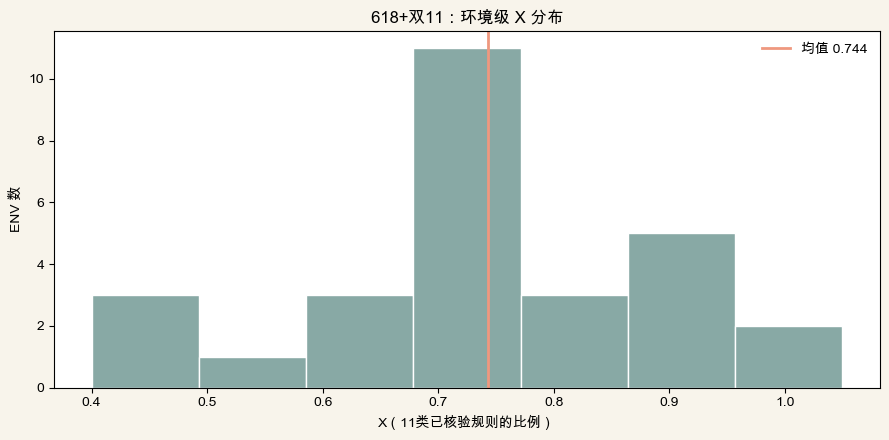

,ENV,X_ENV,observed_category_count,unknown_category_count
25,抖音|618|2024,0.454545,5,6
16,抖音|双11|2025,0.454545,5,6
15,淘宝|双11|2023,0.454545,5,6
18,拼多多|双11|2025,0.545455,6,5
20,京东|双11|2025,0.636364,7,4
5,淘宝|618|2023,0.636364,7,4
8,抖音|618|2026,0.636364,7,4
17,拼多多|618|2024,0.727273,8,3
14,淘宝|双11|2022,0.727273,8,3
19,拼多多|双11|2023,0.727273,8,3


In [14]:
_, env = h.compute_x()
env = env.loc[env.event.isin(scope.SCORING_EVENTS)].copy()
fig, ax = plt.subplots(figsize=(9, 4.5), facecolor=PAPER)
ax.hist(env.X_ENV.dropna(), bins=np.linspace(0.4, 1.05, 8), color=TEAL, edgecolor='white')
ax.axvline(env.X_ENV.mean(), color=CORAL, lw=2, label=f'均值 {env.X_ENV.mean():.3f}')
ax.set(title='618+双11：环境级 X 分布', xlabel='X（11类已核验规则的比例）', ylabel='ENV 数')
ax.legend(frameon=False); fig.tight_layout(); plt.show()
display(env[['ENV','X_ENV','observed_category_count','unknown_category_count']].sort_values('X_ENV'))


## Y：弱标签、样本外测试、最终评分


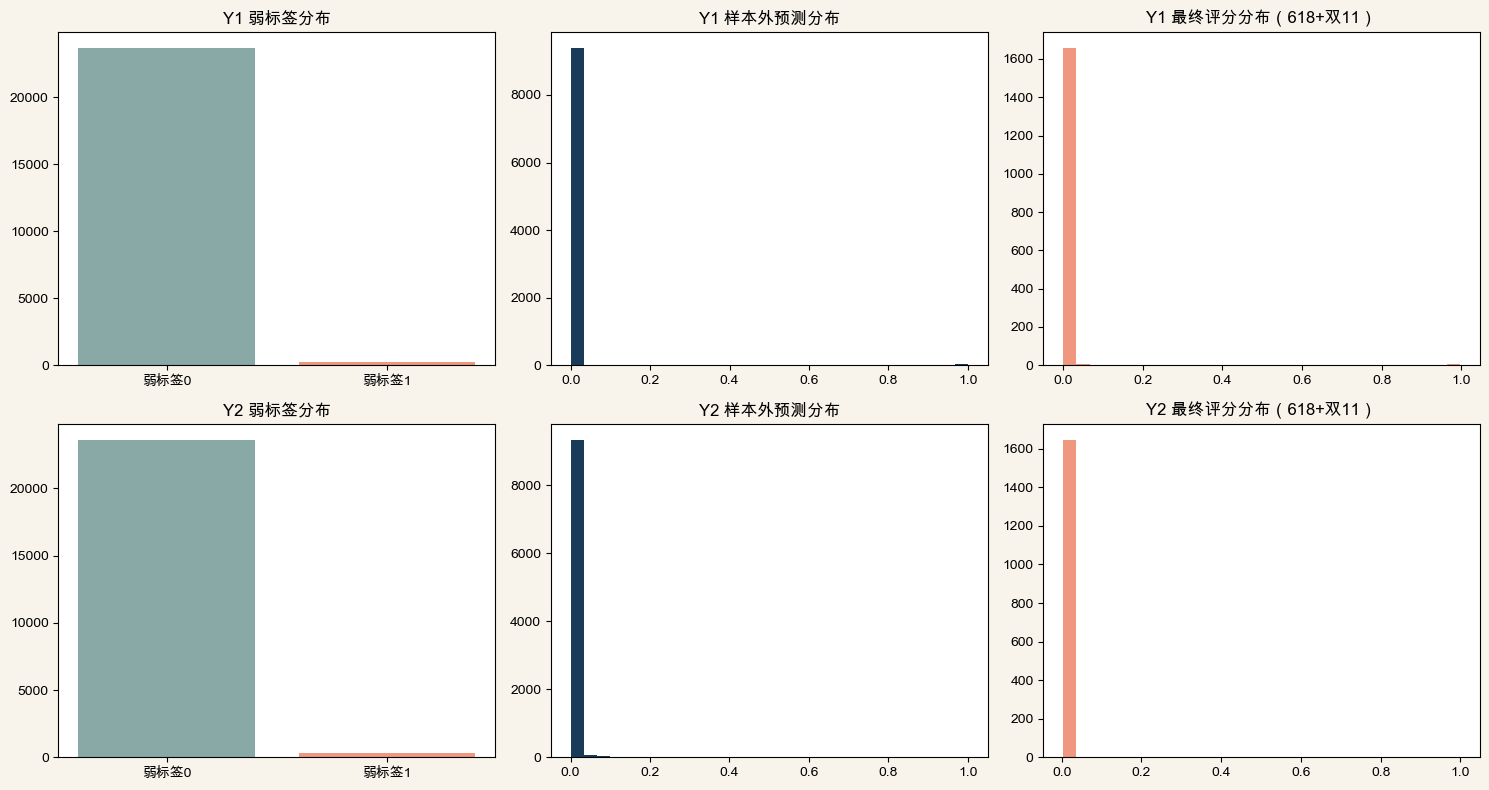

,目标,全池N,弱标签正例,训练N,测试N,测试正例,ROC-AUC,AP,最终评分N
0,Y1,23910,240,14358,9552,94,0.993907,0.765907,1674
1,Y2,23910,309,14337,9573,124,0.970173,0.584325,1678


In [16]:
summary_rows = []
fig, axes = plt.subplots(2, 3, figsize=(15, 8), facecolor=PAPER)
for r, name in enumerate(('Y1', 'Y2')):
    pool, plan = h.load_target(name)
    test = pool.set_index('row_id').loc[plan['test_ids']].reset_index()
    frozen = pd.read_csv(h.target_folder(name) / '冻结新版测试集评分.csv')
    test = test.merge(frozen[['row_id','probability']], on='row_id', validate='one_to_one')
    final = scope.scoring_pool(name)
    counts = pool.weak_label.value_counts().reindex([0,1], fill_value=0)
    axes[r,0].bar(['弱标签0','弱标签1'], counts, color=[TEAL,CORAL]); axes[r,0].set_title(f'{name} 弱标签分布')
    axes[r,1].hist(test.probability, bins=30, color=BLUE); axes[r,1].set_title(f'{name} 样本外预测分布')
    axes[r,2].hist(final.score, bins=30, color=CORAL); axes[r,2].set_title(f'{name} 最终评分分布（618+双11）')
    summary_rows.append({'目标':name,'全池N':len(pool),'弱标签正例':int(pool.weak_label.sum()),'训练N':len(plan['train_ids']),'测试N':len(test),'测试正例':int(test.weak_label.sum()),'ROC-AUC':roc_auc_score(test.weak_label,test.probability),'AP':average_precision_score(test.weak_label,test.probability),'最终评分N':len(final)})
fig.tight_layout(); plt.show()
display(pd.DataFrame(summary_rows))


## λ：连续损失曲线
曲线在对数 λ 网格上平滑连接交叉验证平均损失；连续线只改善阅读，不增加新的实测 λ 点。


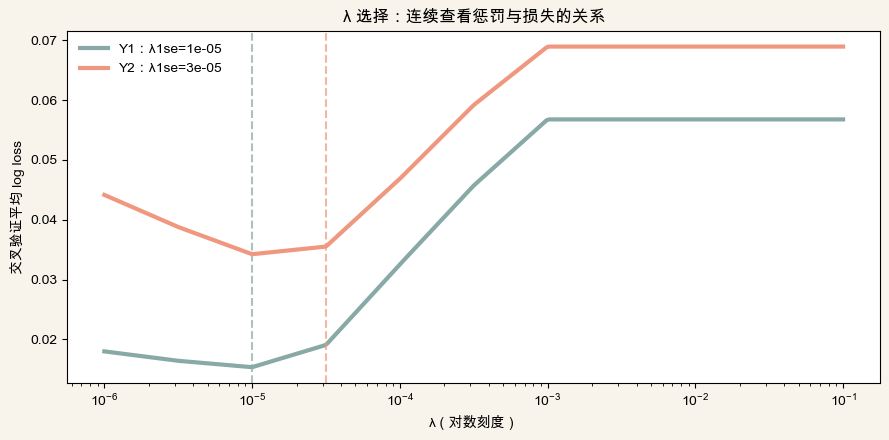

In [33]:
fig, ax = plt.subplots(figsize=(9, 4.5), facecolor=PAPER)
for name, folder, color in [('Y1','Y1_多花',TEAL),('Y2','Y2_求助',CORAL)]:
    selection = json.loads((h.DATA/'03_Y模型数据'/folder/'冻结新版模型/模型选择.json').read_text())
    grid, loss = np.array(selection['grid']), np.array(selection['mean_logloss'])
    continuous_grid = np.geomspace(grid.min(), grid.max(), 300)
    continuous_loss = np.interp(np.log10(continuous_grid), np.log10(grid), loss)
    ax.plot(continuous_grid, continuous_loss, lw=3, color=color, label=f'{name}：λ1se={selection["lambda_1se"]:.0e}')
    ax.axvline(selection['lambda_1se'], color=color, ls='--', alpha=.7)
ax.set_xscale('log'); ax.set(xlabel='λ（对数刻度）', ylabel='交叉验证平均 log loss', title='λ 选择：连续查看惩罚与损失的关系')
ax.legend(frameon=False); fig.tight_layout(); plt.show()


## 双11关联：散点图与纵向变化


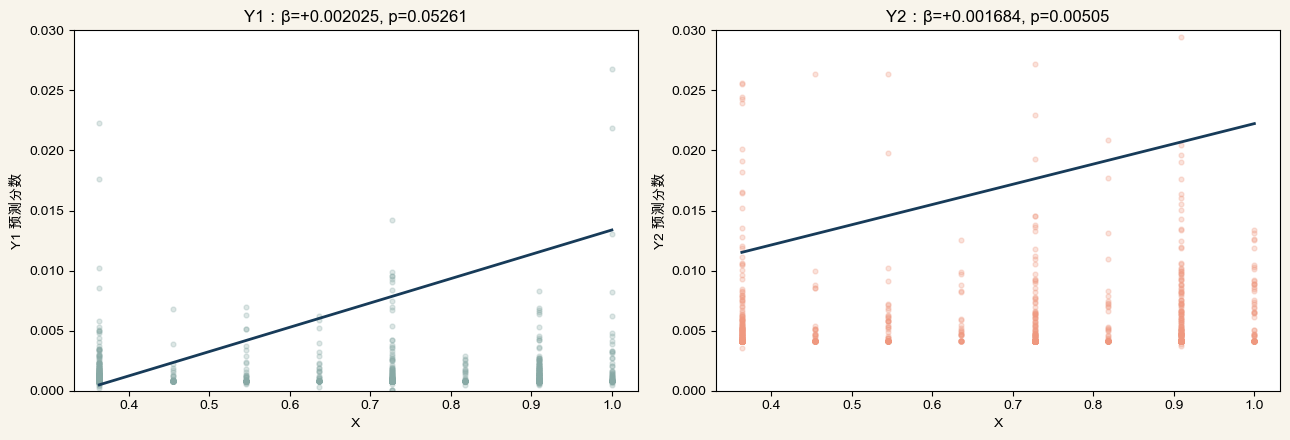

,目标,评论关联β（X+0.1）,评论p,纵向β（X+0.1）,年份变化组数
0,Y1,0.002025,0.05261,0.000236,12
1,Y2,0.001684,0.00505,0.001353,12


In [38]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), facecolor=PAPER)
association_summary = []
for ax, name, color in zip(axes, ('Y1','Y2'), (TEAL,CORAL)):
    rows, result = scope.comment_association(name)
    ax.scatter(rows.X, rows.score, s=12, alpha=.28, color=color)
    coef = np.polyfit(rows.X, rows.score, 1)
    xs = np.linspace(rows.X.min(), rows.X.max(), 100)
    ax.plot(xs, np.polyval(coef,xs), color=BLUE, lw=2)
    ax.set(title=f'{name}：β={result["slope_score_units_per_0_1_x"]:+.6f}, p={result["p_raw"]:.5f}', xlabel='X', ylabel=f'{name} 预测分数', ylim=(0, 0.03))
    long = scope.longitudinal_association(name)
    association_summary.append({'目标':name,'评论关联β（X+0.1）':result['slope_score_units_per_0_1_x'],'评论p':result['p_raw'],'纵向β（X+0.1）':long['slope_score_units_per_0_1_X'],'年份变化组数':long['n_adjacent_year_changes']})
fig.tight_layout(); plt.show()
display(pd.DataFrame(association_summary))
